In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier

## MNIST 숫자 손글씨를 앙상블(보팅) 알고리즘에 사용할 데이터를 준비한다.

MNIST 숫자 손글씨 데이터셋을 불러온다.

In [3]:
raw_data = datasets.load_digits()
x_train, x_test, y_train, y_test = train_test_split(raw_data.data, raw_data.target, random_state=0)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(1347, 64) (450, 64) (1347,) (450,)


학습 데이터와 테스트 데이터를 아래와 같이 스케일링 해도 되지만 숫자 손글씨 데이터는 한 픽셀의 최대값이 15이고 값의 범위가 0 ~ 15이므로 스케일러를 사용하지 않고 최대값인 15로 나눈는 방법도 가능하다.

```
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
```

In [4]:
x_train /= 15
x_test /= 15

## 보팅 알고리즘에 사용할 개별 모델의 정확도를 측정한다.

k최근접 이웃

In [5]:
model_kn = KNeighborsClassifier(n_neighbors=299)
model_kn.fit(x_train, y_train)
predict = model_kn.predict(x_test)
accuracy_kn = accuracy_score(y_test, predict)
print(f'k최근접 이웃 정확도: {accuracy_kn:.2%}')

k최근접 이웃 정확도: 83.33%


서포트 벡터 머신

In [11]:
model_sv = SVC(probability=True, gamma=0.001)
model_sv.fit(x_train, y_train)
predict = model_sv.predict(x_test)
accuracy_svm = accuracy_score(y_test, predict)
print(f'서포트 벡터 머신 정확도: {accuracy_svm:.2%}')

서포트 벡터 머신 정확도: 69.78%


의사결정 트리

In [7]:
model_dt = DecisionTreeClassifier(max_depth=8)
model_dt.fit(x_train, y_train)
predict = model_dt.predict(x_test)
accuracy_dt = accuracy_score(y_test, predict)
print(f'의사결정 트리 정확도: {accuracy_dt:.2%}')

의사결정 트리 정확도: 81.56%


나이브 베이즈

In [8]:
model_nb = GaussianNB()
model_nb.fit(x_train, y_train)
predict = model_nb.predict(x_test)
accuracy_nb = accuracy_score(y_test, predict)
print(f'가우시안 나이브 베이즈 정확도: {accuracy_nb:.2%}')

가우시안 나이브 베이즈 정확도: 83.33%


## 각 개별 모델의 사용한 보팅 알고리즘의 정확도를 측정한다.

하드 보팅

In [9]:
model_hv = VotingClassifier(
    estimators=[('kn', model_kn), ('sv', model_sv), ('dt', model_dt), ('nb', model_nb)], voting='hard', weights=[1, 1, 1, 1]
)
model_hv.fit(x_train, y_train)
predict = model_hv.predict(x_test)
accuracy_hv = accuracy_score(y_test, predict)
print(f'하드 보팅 정확도: {accuracy_hv:.2%}')

하드 보팅 정확도: 87.33%


소프트 보팅

In [12]:
model_sv = VotingClassifier(
    estimators=[('kn', model_kn), ('sv', model_sv), ('dt', model_dt), ('nb', model_nb)], voting='soft', weights=[1, 1, 1, 1]
)
model_sv.fit(x_train, y_train)
predict = model_sv.predict(x_test)
accuracy_sv = accuracy_score(y_test, predict)
print(f'소프트 보팅 정확도: {accuracy_sv:.2%}')

소프트 보팅 정확도: 89.33%


## 단일 모델(k최근접 이웃, 서포트 벡터 머신, 의사결정 트리, 가우시안 나이브 베이즈)와 보팅 앙상블(하드, 소프트) 모델들의 정확도 시각화

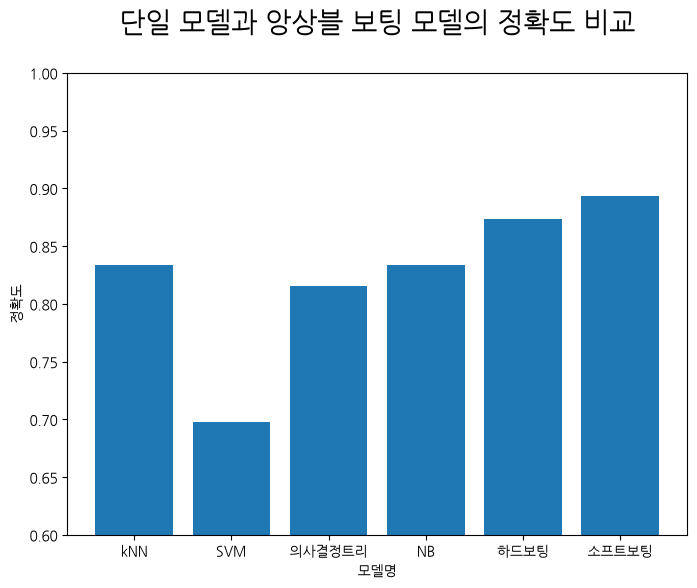

In [20]:
plt.figure(figsize=[8, 6])
plt.bar(
    x = np.arange(6),
    height=[accuracy_kn, accuracy_svm, accuracy_dt, accuracy_nb, accuracy_hv, accuracy_sv]
)
plt.title('단일 모델과 앙상블 보팅 모델의 정확도 비교', pad=30, fontsize=20)
plt.xlabel('모델명')
plt.ylabel('정확도')
plt.xticks(np.arange(6), ['kNN', 'SVM', '의사결정트리', 'NB', '하드보팅', '소프트보팅'])
plt.ylim(0.6, 1.0)
plt.show()